# Cell-type deconvolution of the Visium spots with RCTD

**Goal**: estimate, for every Visium spot, the proportion of each cell type identified in the single-cell data (notebook 01), map these proportions on the section, and check that they agree with the histology and the spatial domains (notebook 02). This is the step that links the two datasets.

**Why it is needed.** A 55 µm spot contains 5 to 20 cells, so its counts are a mixture. The single-cell cells and the Visium spots come from different sections of the same block: no individual cell can be matched to a spot. What links the two datasets are the same cell types (same tumour) and the same genes (same probe panel).

**How RCTD works** (Cable et al., *Nature Biotechnology* 2022):
1. from the annotated single-cell reference, it computes the **mean expression profile** of each cell type;
2. it keeps the genes that differ between cell types;
3. it estimates a gene-wise **platform effect** (capture differences between Chromium Flex and Visium) by comparing the sum of all spots with the reference profiles;
4. for each spot, it finds the non-negative weights of the cell types whose mixture makes the observed counts most likely (Poisson model of molecule counts, with an extra log-normal noise term that absorbs genes that do not fit);
5. the weights are normalised to sum to 1: the cell-type proportions of the spot (proportions of RNA, close to but not identical to proportions of cells).

In `full` mode, any number of cell types can be present in a spot, which suits Visium. RCTD needs **raw integer counts** and can only find the cell types present in the reference.

Inputs: `data/sc_annotated.h5ad` (notebook 01) and `data/visium_clustered.h5ad` (notebook 02). RCTD itself (R package spacexr) runs in the Docker image built from `docker/rctd/Dockerfile`, through the script `bin/rctd.R`.

In [1]:
import gc
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.io
import scipy.sparse as sp
import squidpy as sq

# Repository root = the first parent folder that contains envs/python.yml
ROOT = Path.cwd()
while not (ROOT / "envs" / "python.yml").exists():
    if ROOT == ROOT.parent:   # reached "/" without finding it
        raise FileNotFoundError("Run this notebook from inside the repository")
    ROOT = ROOT.parent
DATA = ROOT / "data"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sc.settings.set_figure_params(dpi=80, frameon=False)

# Annotated single-cell reference (notebook 01) and clustered Visium spots (notebook 02)
sc_ad = sc.read_h5ad(DATA / "sc_annotated.h5ad")
vis = sc.read_h5ad(DATA / "visium_clustered.h5ad")
print(sc_ad.n_obs, "cells |", vis.n_obs, "spots")

/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'n_jobs' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/home/juliette/miniforge3/envs/scspatial-python/lib/python3.11/site-packages/docrep/decorators.py:43: SyntaxWarning: 'show_progress_bar' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


29387 cells | 4981 spots


## 1. Exporting both datasets for R

RCTD is an R package, and the data are Python AnnData objects. They are exchanged as a sparse **Matrix Market** file (`counts.mtx`, read in R with `Matrix::readMM`) plus the list of genes and the list of cell or spot barcodes. Two points matter:
- RCTD models molecule counts, so the **raw integer counts** of `layers["counts"]` are exported, never the normalised `X`; an assertion stops the notebook if the values are not integers;
- R stores count matrices as **genes × cells**, the transpose of AnnData (cells × genes), hence `.T`.

In [2]:
def export_counts(adata, outdir):
    """Write the raw counts of an AnnData object in Matrix Market format, with gene and barcode lists."""
    outdir.mkdir(parents=True, exist_ok=True)
    counts = adata.layers["counts"]                      # raw counts, saved before normalisation
    counts = sp.csr_matrix(counts) if not sp.issparse(counts) else counts
    assert np.allclose(counts.data, np.round(counts.data)), "these are not integer counts!"
    scipy.io.mmwrite(outdir / "counts.mtx", counts.T.tocoo())   # transposed: genes x cells, as expected by R
    pd.Series(adata.var_names).to_csv(outdir / "genes.txt", index=False, header=False)     # row names
    pd.Series(adata.obs_names).to_csv(outdir / "barcodes.txt", index=False, header=False)  # column names

**The reference.** Two labels of notebook 01 are not cell types and are excluded: **Doublets** and **Low_quality** (a "doublet" profile would let RCTD explain spots with a mixture that is not a real cell). RCTD also requires at least 25 cells per type. Only the mean profile of each type is used, so each type is subsampled to at most 2,000 cells: this divides the memory needed by R by about three. The spots are exported with their coordinates.

In [3]:
n_per_type = sc_ad.obs["cell_type"].value_counts()
print(n_per_type)

NOT_CELL_TYPES = ["Doublets", "Low_quality"]          # labels, not cell types
keep_types = n_per_type[n_per_type >= 25].index      # types with at least 25 cells (RCTD minimum)
keep_types = keep_types.drop(NOT_CELL_TYPES)
print("cell types kept:", list(keep_types))
ref = sc_ad[sc_ad.obs["cell_type"].isin(keep_types)]

# Random subsample of at most 2,000 cells per type (seeded, so reproducible)
idx = ref.obs.groupby("cell_type", observed=True, group_keys=False).apply(
    lambda d: d.sample(min(len(d), 2000), random_state=0)).index
ref = ref[idx]
print("cells in the reference:", ref.n_obs)

# Reference: counts + cell type of each cell
export_counts(ref, DATA / "reference")
ref.obs[["cell_type"]].to_csv(DATA / "reference" / "cell_types.csv")

# Spots: counts + (x, y) position of each spot
export_counts(vis, DATA / "spatial_counts")
coords = pd.DataFrame(vis.obsm["spatial"][:, :2], index=vis.obs_names, columns=["x", "y"])
coords.to_csv(DATA / "spatial_counts" / "coords.csv")
sorted(p.name for p in (DATA / "reference").iterdir()), sorted(p.name for p in (DATA / "spatial_counts").iterdir())

cell_type
Tumor_epithelial    8774
T_cells             5266
Macrophages         4006
Doublets            2413
Fibroblasts         2291
Myoepithelial       1849
Plasma_cells        1468
Endothelial         1331
B_cells             1143
Low_quality          406
Plasmacytoid_DC      183
LAMP3_DC             130
Mast_cells           127
Name: count, dtype: int64
cell types kept: ['Tumor_epithelial', 'T_cells', 'Macrophages', 'Fibroblasts', 'Myoepithelial', 'Plasma_cells', 'Endothelial', 'B_cells', 'Plasmacytoid_DC', 'LAMP3_DC', 'Mast_cells']
cells in the reference: 14231


/tmp/ipykernel_924/2361863548.py:11: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  idx = ref.obs.groupby("cell_type", observed=True, group_keys=False).apply(


(['barcodes.txt', 'cell_types.csv', 'counts.mtx', 'genes.txt'],
 ['barcodes.txt', 'coords.csv', 'counts.mtx', 'genes.txt'])

**Observations.** 11 cell types are kept (the curated Perivascular type was assigned to no cluster in notebook 01) and the reference holds **14,231 cells**: 2,000 for each of the four largest types, all cells for the others.

R runs in a Docker container that shares the memory of WSL with this notebook, so the large objects that are no longer needed are deleted first.

In [4]:
# The reference is written to disk: free the memory of the single-cell objects before R starts
del sc_ad, ref
gc.collect()

1325

## 2. Running RCTD in its container

The image `scspatial-rctd:0.1` (R 4.4 with spacexr) is built once from `docker/rctd/Dockerfile`. It contains the software only: the script `bin/rctd.R` and the data are seen by the container through the mounted repository.
- `--rm`: the container is deleted when it stops (the results are written to the mounted folder);
- `-u $(id -u):$(id -g)`: files are written with the current user, not root;
- `-v ROOT:/work -w /work`: mounts the repository inside the container and works from there.

`bin/rctd.R` reads the exported files, builds the `Reference` and `SpatialRNA` objects, runs `create.RCTD` and `run.RCTD(doublet_mode = "full")` and writes the normalised weights. It takes 15 to 30 minutes with 4 cores.

In [5]:
# Delete any previous result, so that an old file is never loaded by mistake if RCTD fails
(DATA / "rctd_weights.csv").unlink(missing_ok=True)

cmd = (
    f"docker run --rm -u $(id -u):$(id -g) -v {ROOT}:/work -w /work scspatial-rctd:0.1 "
    "Rscript bin/rctd.R --reference data/reference --spatial data/spatial_counts --cores 4 "
    "--out-weights data/rctd_weights.csv --out-rds data/rctd_results.rds"
)
print(cmd)
# Run the command as in a terminal and keep the end of R's messages
res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
print(res.stdout[-3000:], res.stderr[-3000:])

docker run --rm -u $(id -u):$(id -g) -v /home/juliette/projets/sc-spatial-breast-cancer:/work -w /work scspatial-rctd:0.1 Rscript bin/rctd.R --reference data/reference --spatial data/spatial_counts --cores 4 --out-weights data/rctd_weights.csv --out-rds data/rctd_results.rds

The command 'docker' could not be found in this WSL 2 distro.
We recommend to activate the WSL integration in Docker Desktop settings.

For details about using Docker Desktop with WSL 2, visit:

https://docs.docker.com/go/wsl2/

 


## 3. Loading the proportions

`rctd_weights.csv` has one row per spot and one column per cell type. Spots with fewer than 100 molecules would be skipped by RCTD; here all 4,981 spots are kept. Each cell type is added as a column of `vis.obs`, so that it can be drawn on the section.

In [6]:
w = pd.read_csv(DATA / "rctd_weights.csv", index_col=0)   # rows = spot barcodes
print(w.shape)
# Keep the spots present in both tables, in the same order
common = vis.obs_names.intersection(w.index)
vis = vis[common].copy()
w = w.loc[common]

# One column per cell type in vis.obs (same order as w, so .values can be used)
for ct in w.columns:
    vis.obs[ct] = w[ct].values
w.head()

FileNotFoundError: [Errno 2] No such file or directory: '/home/juliette/projets/sc-spatial-breast-cancer/data/rctd_weights.csv'

## 4. Checking that the result is credible

1. The proportions of each spot sum to 1.
2. Tumour cells dominate where the H&E image and the spatial domains show tumour.
3. Myoepithelial cells accompany tumour cells in the DCIS domains (in situ carcinoma is still surrounded by the myoepithelial layer) and are absent from the invasive domain (tumour cells have crossed it).
4. The mean composition of each spatial domain of notebook 02 matches its name (section 5).

In [ ]:
# Sum over the 11 cell types for each spot (axis=1: along each row)
proportion_sum = w.sum(axis=1)
print(proportion_sum.describe())

count    4.981000e+03
mean     1.000000e+00
std      5.287732e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64


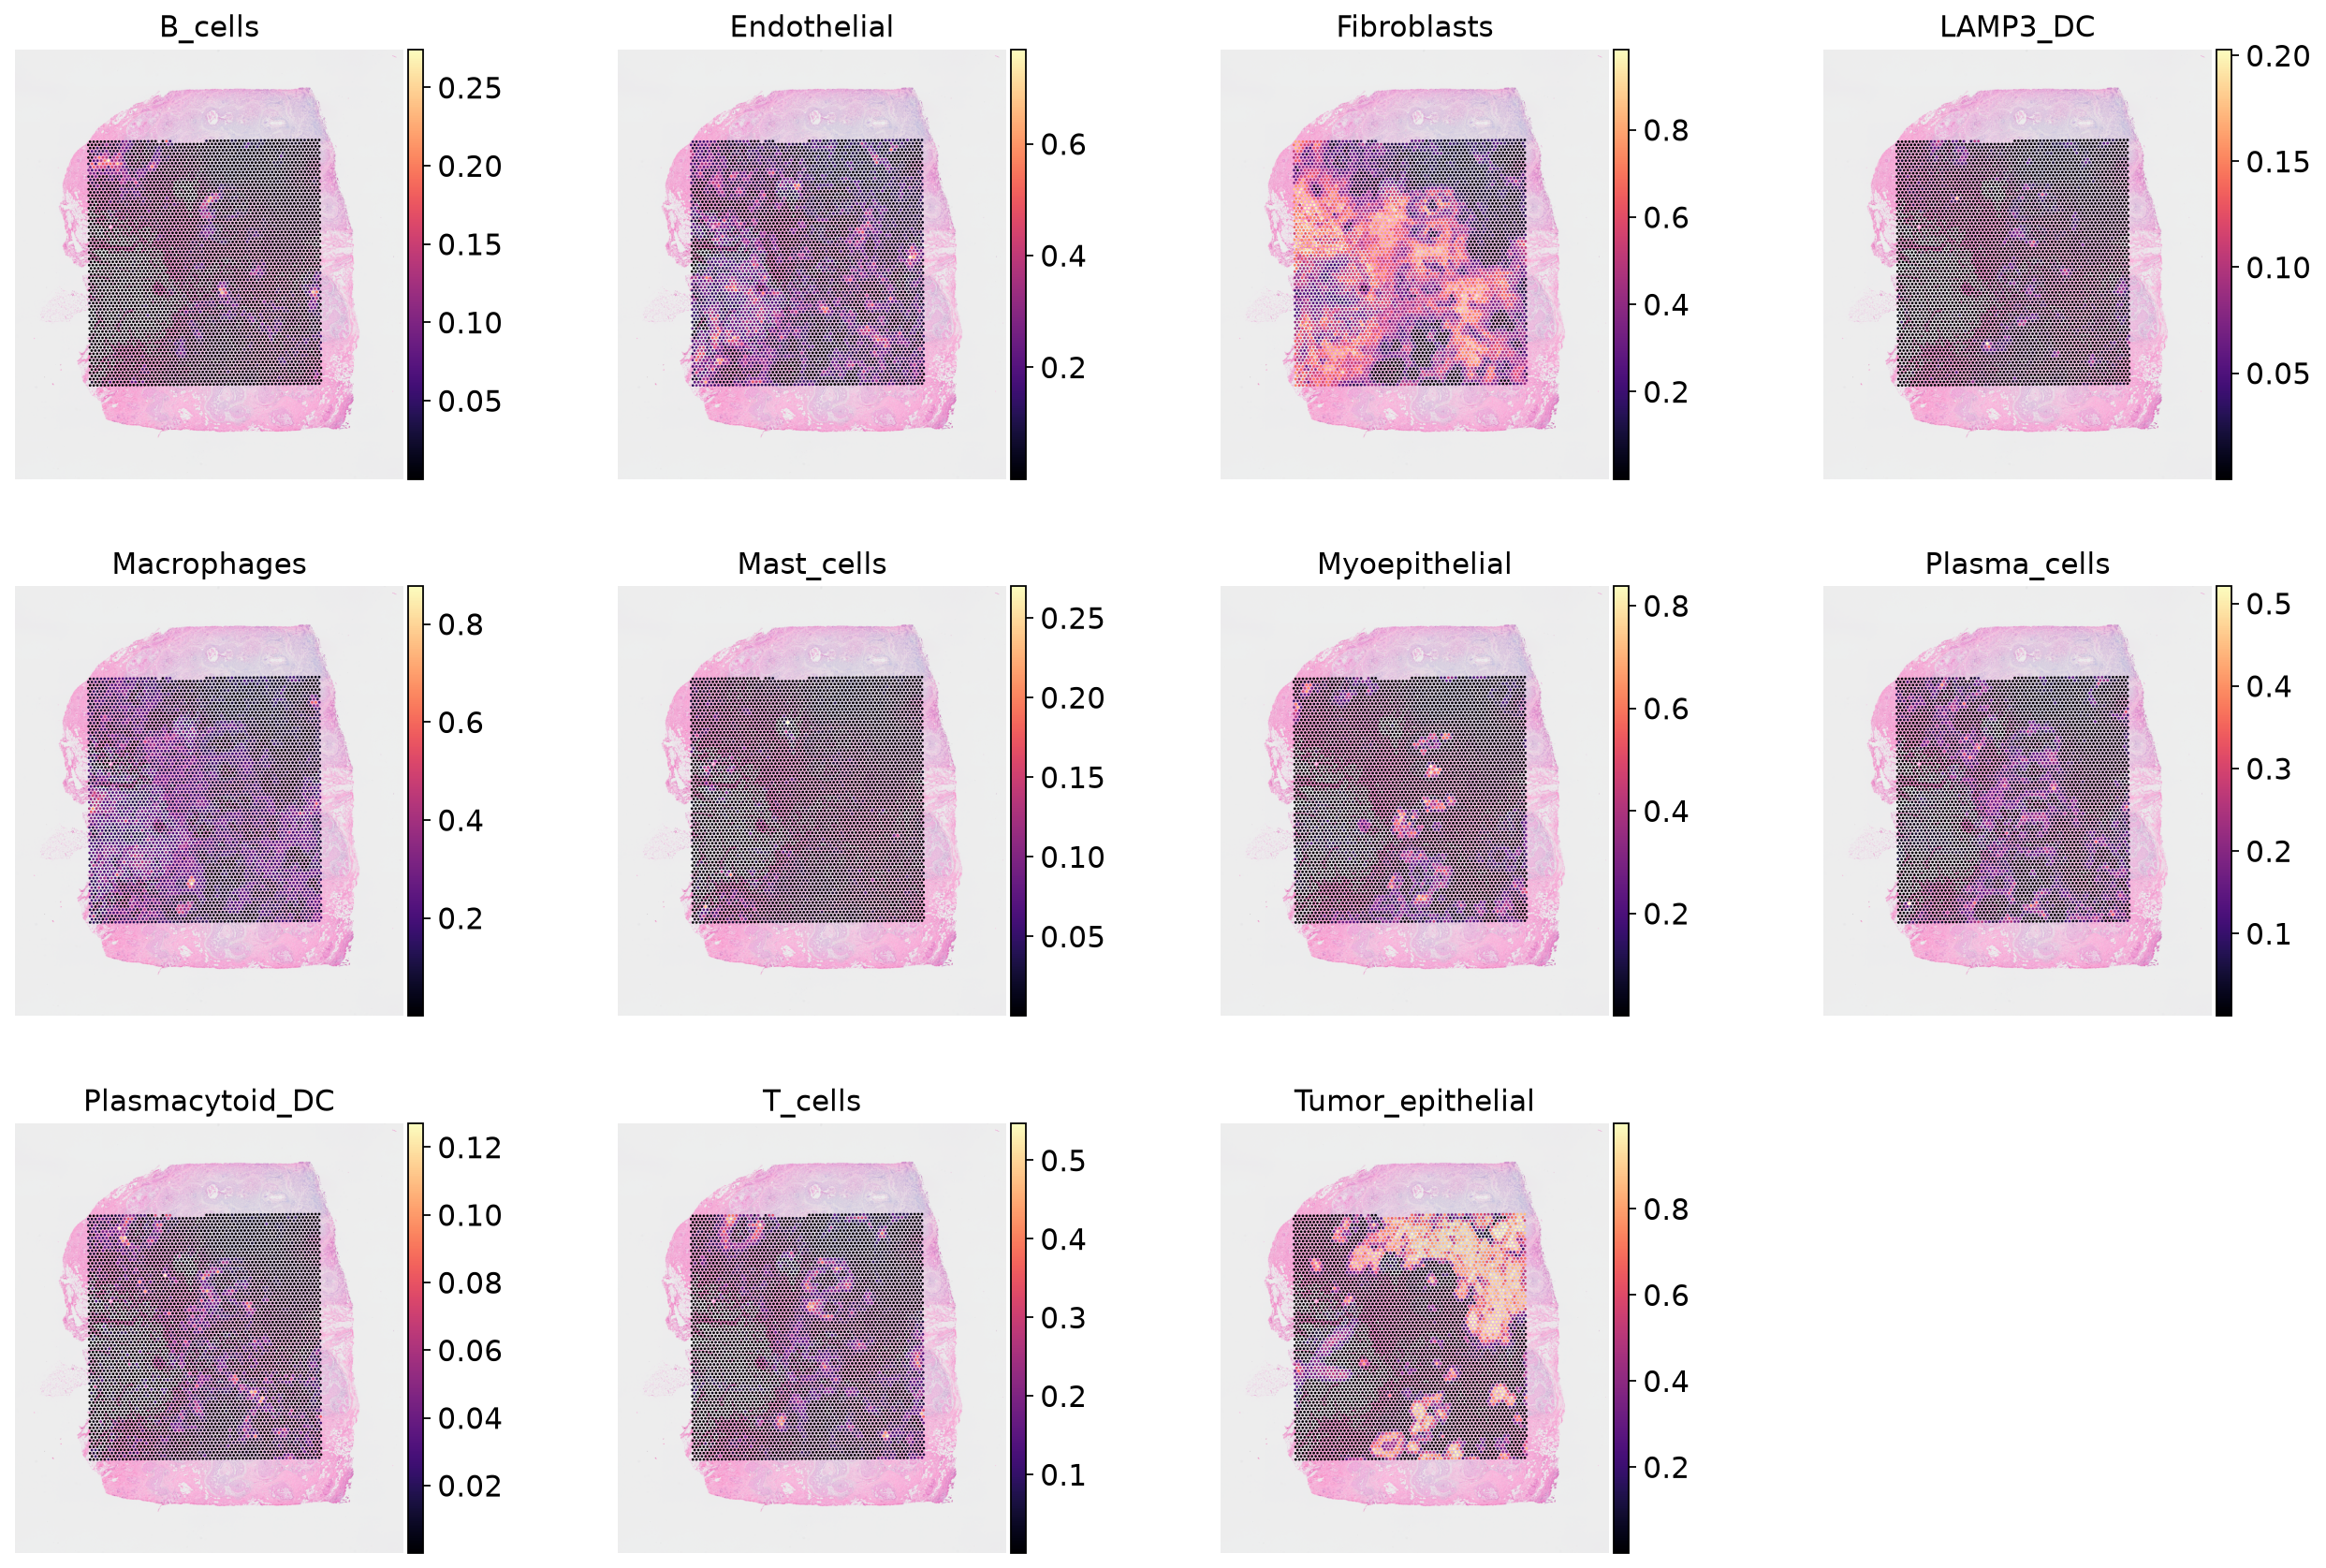

In [ ]:
# One map per cell type: each spot coloured by the proportion of that type.
# Each map has its own colour scale: check the maximum of each colour bar.
sq.pl.spatial_scatter(vis, color=list(w.columns), ncols=4, cmap="magma", figsize=(4, 4))
plt.savefig(FIG / "03_rctd_proportions.png", dpi=150, bbox_inches="tight")

**Observations.** All spots sum to 1. Tumour cells reach 80-100 % in the invasive region at the top right and in the duct groups of both DCIS. Fibroblasts dominate between the ducts and on the whole left side, which is **adipose tissue**: the reference has no adipocytes (they do not survive dissociation), so fat spots are explained by the closest types. T cells form arcs around the central ducts and an aggregate at the top left, the shape of the immune domain of notebook 02. Macrophages are diffuse in the stroma, endothelial cells form scattered spots (vessels), and rare types (B cells, LAMP3+ DCs, pDCs, mast cells) never exceed 12-27 % of a spot.

Tumour and myoepithelial cells side by side, next to the H&E image:

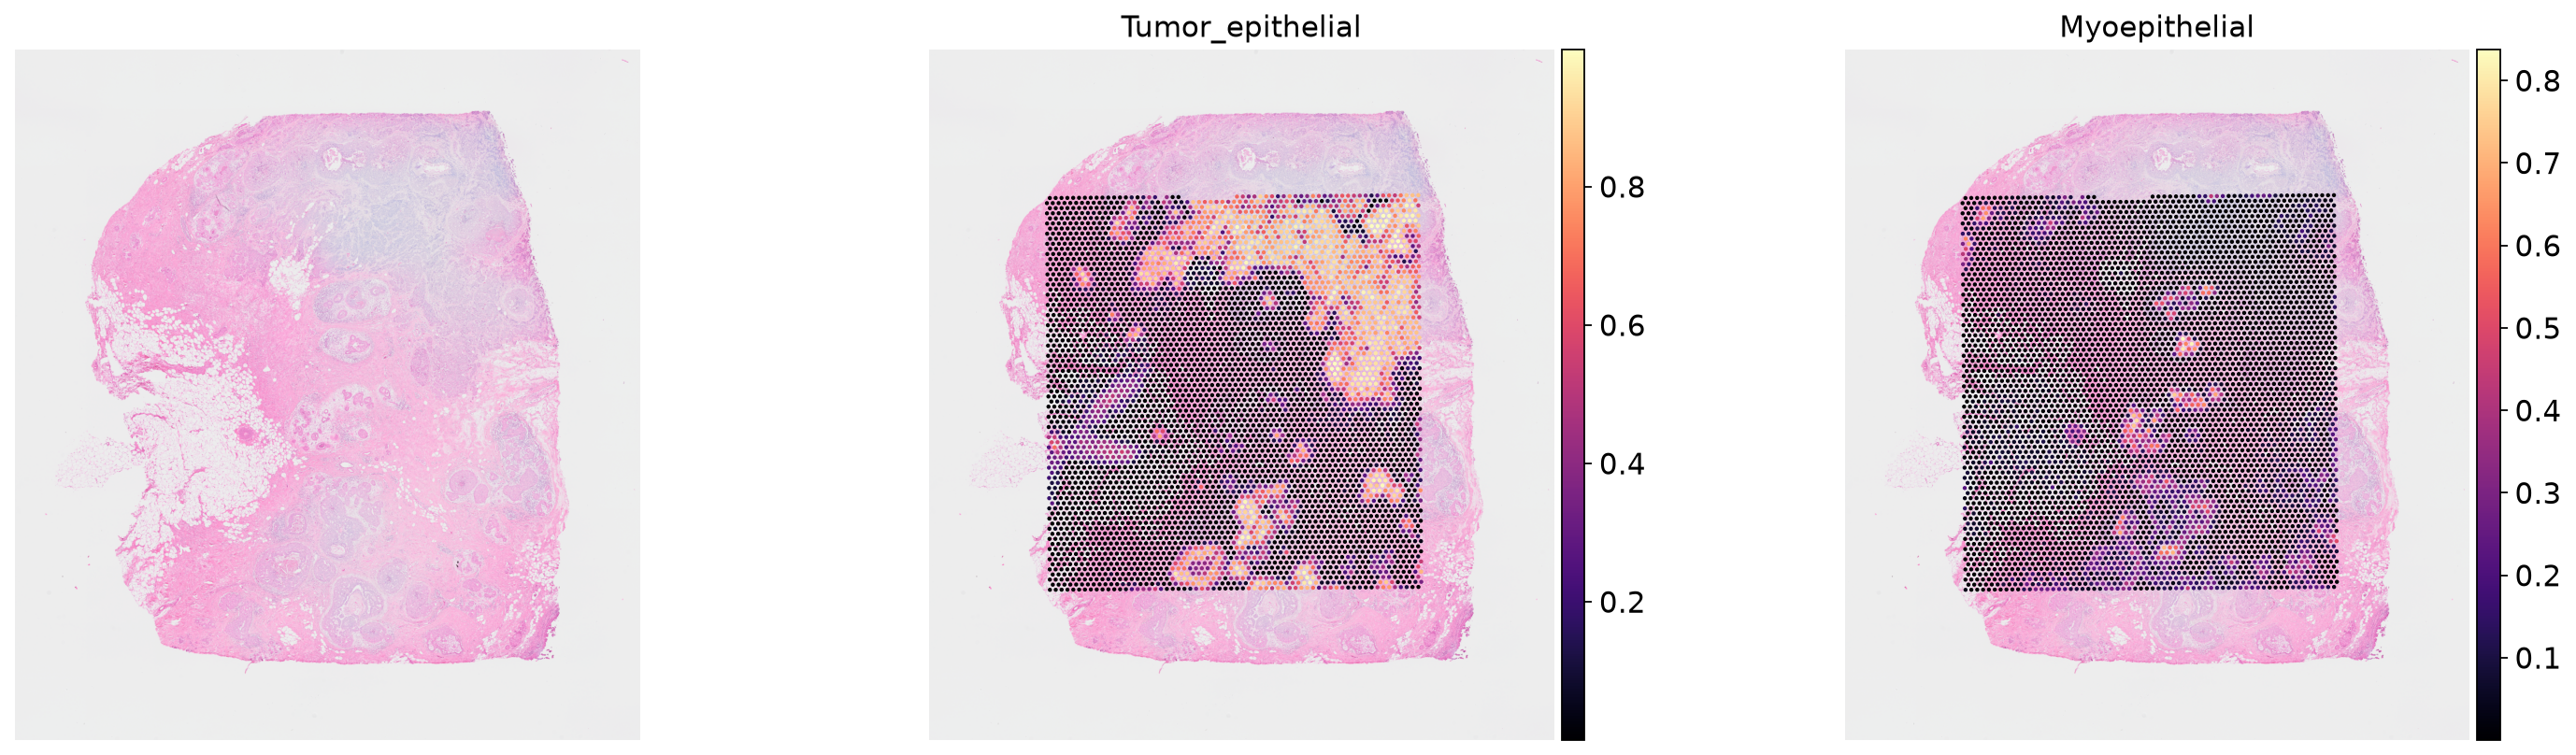

In [ ]:
# H&E image (None), tumour and myoepithelial proportions
sq.pl.spatial_scatter(vis, color=[None, "Tumor_epithelial", "Myoepithelial"], ncols=3, cmap="magma", figsize=(6, 6))
plt.savefig(FIG / "03_tumour_myoepithelial.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations.** The invasive region is almost pure tumour with no myoepithelial signal, whereas myoepithelial cells (20-60 % of some spots) appear in and around the DCIS ducts. They do not draw sharp rings: the myoepithelial layer is one cell thick (~10 µm), much thinner than a 55 µm spot, so each border spot mixes a few myoepithelial cells with tumour cells and stroma. Mean proportions per published domain measure the effect directly:

In [ ]:
# Mean tumour and myoepithelial proportions in each domain published by 10x
vis.obs.groupby("published_domain", observed=True)[["Tumor_epithelial", "Myoepithelial"]].mean().round(2)

,Tumor_epithelial,Myoepithelial
published_domain,,
DCIS #1,0.51,0.22
DCIS #2,0.66,0.11
adipocytes,0.03,0.02
immune,0.02,0.01
invasive,0.87,0.00
mixed,0.17,0.16
mixed/invasive,0.58,0.00
myoepithelial/stromal/immune,0.00,0.16
stromal,0.01,0.00


**Observations.** Both DCIS domains combine tumour cells with myoepithelial cells (**DCIS #1**: 51 % tumour, 22 % myoepithelial; **DCIS #2**: 66 % and 11 %), whereas the **invasive** domain is 87 % tumour with **no myoepithelial signal** (0 %, also in "mixed/invasive"). RCTD, which never saw the image or the published domains, recovers the histological feature that defines invasion: tumour cells have crossed the myoepithelial layer. Non-tumour domains contain ≤ 3 % tumour cells.

## 5. Cell-type composition of the spatial domains

Mean proportion of each cell type in each spatial domain of notebook 02 (Leiden, resolution 0.8): rows = domains, columns = cell types.

/tmp/ipykernel_1149/3572537201.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  comp = w.groupby(vis.obs["leiden"].values).mean()


,B_cells,Endothelial,Fibroblasts,LAMP3_DC,Macrophages,Mast_cells,Myoepithelial,Plasma_cells,Plasmacytoid_DC,T_cells,Tumor_epithelial
cluster_spatial,,,,,,,,,,,
0,0.07,0.15,0.44,0.01,0.11,0.01,0.10,0.05,0.02,0.04,0.00
1,0.01,0.09,0.57,0.00,0.14,0.00,0.04,0.05,0.01,0.05,0.03
2,0.02,0.31,0.44,0.00,0.11,0.00,0.01,0.04,0.01,0.05,0.01
3,0.03,0.11,0.39,0.02,0.16,0.01,0.01,0.10,0.03,0.15,0.00
4,0.00,0.06,0.42,0.01,0.06,0.00,0.31,0.03,0.01,0.04,0.06
5,0.00,0.14,0.69,0.00,0.13,0.01,0.00,0.01,0.00,0.01,0.01
6,0.00,0.04,0.70,0.00,0.16,0.01,0.00,0.05,0.01,0.03,0.00
7,0.01,0.13,0.45,0.01,0.18,0.01,0.05,0.10,0.01,0.04,0.00
8,0.00,0.16,0.26,0.01,0.12,0.00,0.00,0.03,0.00,0.05,0.37


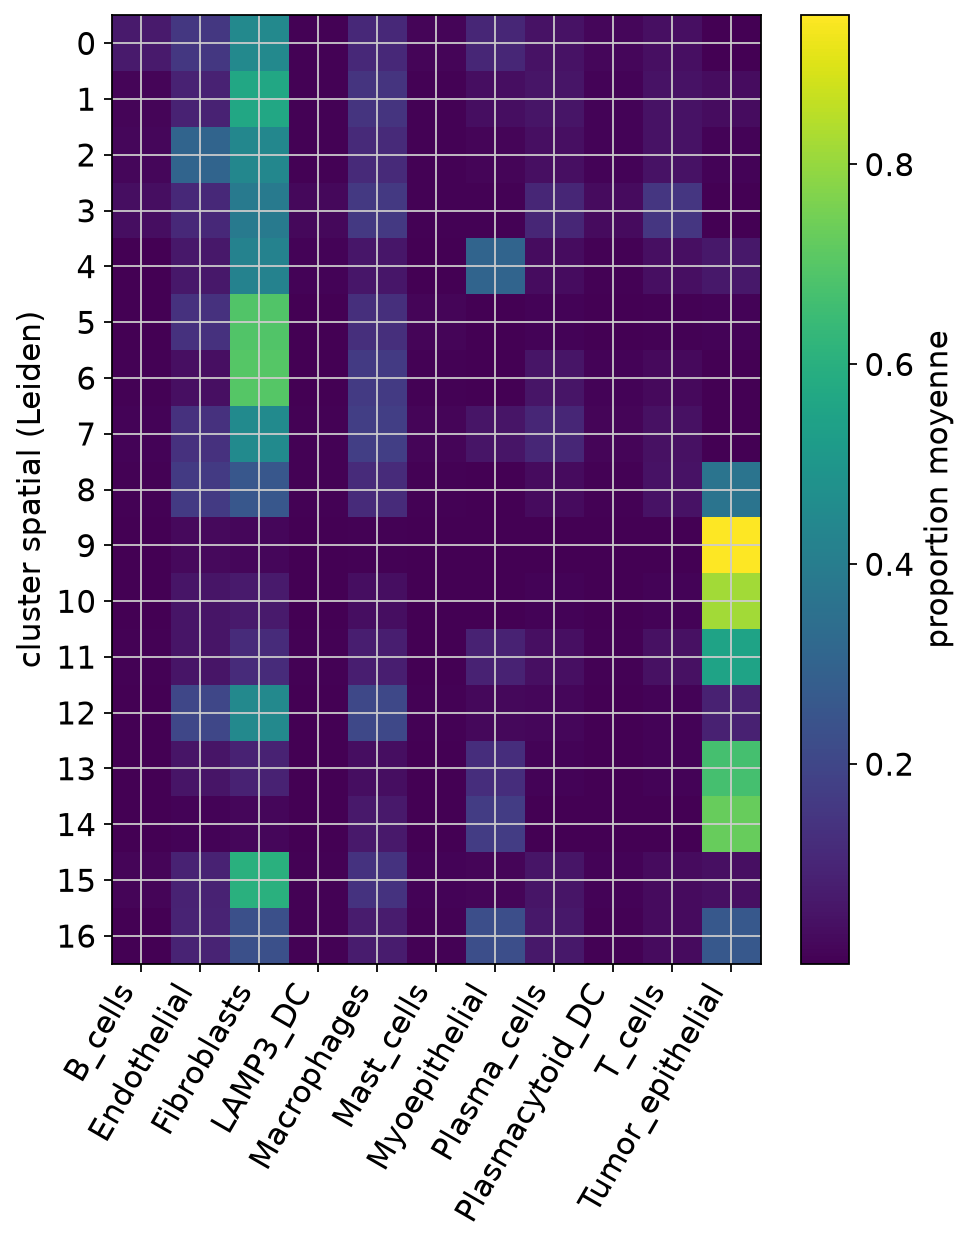

In [ ]:
# Mean proportion of each cell type in each spatial domain
comp = w.groupby(vis.obs["leiden"].values).mean()
comp.index.name = "spatial_domain"

fig, ax = plt.subplots(figsize=(1 + 0.5 * comp.shape[1], 1 + 0.4 * comp.shape[0]))
im = ax.imshow(comp.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(comp.shape[1]), comp.columns, rotation=60, ha="right")
ax.set_yticks(range(comp.shape[0]), comp.index)
ax.set_ylabel("spatial domain (Leiden)")
fig.colorbar(im, ax=ax, label="mean proportion")
fig.savefig(FIG / "03_composition_by_domain.png", dpi=150, bbox_inches="tight")
comp.round(2)

**Observations.** Each domain has the composition its name suggested in notebook 02:
- invasive tumour: 9 (95 % tumour) and 10 (82 %); DCIS #2: 13 (67 %) and 11 (55 %), with 9-12 % myoepithelial cells;
- DCIS #1: 14 (73 % tumour, 17 % myoepithelial) is the duct centre, and 16 (26 % tumour, 23 % myoepithelial, 23 % fibroblasts) its periphery;
- duct-stroma interface: 4 has the highest myoepithelial fraction (31 %); tumour-stroma mixture: 8 (37 % tumour, 26 % fibroblasts);
- vessels: 2 has the highest endothelial fraction (31 %); stroma with B cells: 0 has the most B cells (7 %); stroma: 1, 5, 6, 15 (57-70 % fibroblasts);
- immune infiltrate: 3 has the most T cells (15 %), with plasma cells and macrophages; 7 has plasma cells (10 %) and macrophages;
- adipose tissue: 12 is explained as fibroblasts, macrophages and endothelial cells, the limitation of a reference without adipocytes.

Immune cells are always diluted: even in the immune domain, fibroblasts still make up 39 % of the RNA, because a 55 µm spot always captures stroma and small lymphocytes contain little RNA.

The same table for the domains published by 10x, with all cell types:

In [ ]:
# Mean proportion of each cell type in each domain published by 10x
w.groupby(vis.obs["published_domain"].values, observed=True).mean().round(2)

,B_cells,Endothelial,Fibroblasts,LAMP3_DC,Macrophages,Mast_cells,Myoepithelial,Plasma_cells,Plasmacytoid_DC,T_cells,Tumor_epithelial
DCIS #1,0.00,0.05,0.12,0.00,0.05,0.00,0.22,0.03,0.00,0.01,0.51
DCIS #2,0.00,0.04,0.08,0.01,0.05,0.00,0.11,0.02,0.00,0.02,0.66
adipocytes,0.00,0.23,0.47,0.00,0.22,0.01,0.02,0.02,0.00,0.01,0.03
immune,0.06,0.10,0.26,0.03,0.16,0.00,0.01,0.09,0.03,0.24,0.02
invasive,0.00,0.04,0.05,0.00,0.03,0.00,0.00,0.00,0.00,0.01,0.87
mixed,0.00,0.08,0.40,0.00,0.14,0.00,0.16,0.02,0.00,0.02,0.17
mixed/invasive,0.00,0.11,0.16,0.00,0.08,0.00,0.00,0.02,0.00,0.03,0.58
myoepithelial/stromal/immune,0.06,0.13,0.38,0.01,0.15,0.01,0.16,0.05,0.02,0.04,0.00
stromal,0.01,0.05,0.61,0.00,0.16,0.01,0.00,0.09,0.01,0.04,0.01
stromal/endothelial,0.01,0.12,0.65,0.00,0.12,0.01,0.01,0.03,0.01,0.02,0.03


**Observations.** Each published domain contains what its name says: the 10x "immune" domain has the highest T-cell fraction (24 %), with B cells, plasma cells and LAMP3+ DCs; stromal domains are 61-65 % fibroblasts; "stromal/endothelial/immune" combines fibroblasts (40 %), endothelial cells (17 %) and T cells (7 %).

**Conclusion.** RCTD places tumour cells where the H&E image and the spatial domains show tumour (87 % in the invasive domain, 51-66 % in the DCIS domains, ≤ 3 % elsewhere). Myoepithelial cells accompany tumour cells in both DCIS domains, concentrate at the duct-stroma interface and at the periphery of DCIS #1, and are absent from the invasive domain: the deconvolution recovers the loss of the myoepithelial layer that defines invasion. T cells are enriched in the immune domain around the ducts. The single-cell annotation, the spatial domains and the deconvolution, three different methods, tell the same story.

Limitations: no adipocytes or perivascular cells in the reference; proportions describe RNA rather than cell numbers; the myoepithelial layer is thinner than a spot.